# ATO1 Marche Nord — Water Demand & Network Loss Forecasting Pipeline (v2)

## Rolling-origin backtest, leakage-free preprocessing, and combined visualizations

This notebook converts the authors' original script `corrected_pipeline_ATO1_v2.py`
(not distributed separately) into a documented, cell-by-cell notebook. The
underlying logic is unchanged from that script, which had already been validated
on the full dataset (zero errors, sensible NSE/DM-test numbers for all four
experiments) — what's new here is the notebook
structure itself, plus academic citations for the statistical and
deep-learning methods used throughout, none of which were present in the
original script.

### What this version fixed relative to an earlier v1 pipeline

Three problems were found by inspecting v1's actual output:

**Bug 1 — the NSE bar chart showed identical values in both the Fabbisogni
and Perdite panels.** The plotting function filtered metrics by `model`
only, not by `model AND target`, so `.values[0]` always grabbed the first
matching row — which was always the Fabbisogni row, since it appears first
in the `targets` list. Confirmed by reproducing the exact bug against the
printed v1 numbers (the same four values appeared in both panels).

**Bug 2 — the long-horizon (12-month-ahead) experiments produced NSE = NaN
for every model, including the baselines.** With 60 months of data and a
fixed 80/20 train/test split, a 12-step horizon leaves exactly one valid
non-overlapping test window. NSE requires variance across at least two
samples; with n=1 the denominator is exactly zero, so NaN is the
mathematically correct output — the evaluation protocol didn't have enough
data, not a broken model.

**Bug 3 — SARIMA showed NSE = NaN even for the short-horizon experiment,
where 11 real test windows existed.** The baseline SARIMA function produced
a single one-shot forecast and was evaluated against only the *first* test
window — a coding inconsistency, not a genuine SARIMA failure.

**The fix behind all three:** a single rolling-origin (walk-forward)
backtest, used identically by every model — persistence, seasonal-naive,
SARIMA, LSTM, and Transformer. Instead of one fixed 80/20 split, the
forecast origin slides across the available history one month at a time,
generating dozens of independent forecast instances even for a 12-step
horizon. This is the standard remedy for evaluating forecasts on short
records (Tashman, 2000, *Out-of-sample tests of forecasting accuracy: an
analysis and review*, International Journal of Forecasting, 16(4), 437-450;
Bergmeir & Benítez, 2012, *On the use of cross-validation for time series
predictor evaluation*, Information Sciences, 191, 192-213; Hyndman &
Athanasopoulos, 2021, *Forecasting: Principles and Practice*, 3rd ed.,
ch. 5.10).

This design also directly supports a continuous visualization: the
rolling-origin h=1 trace is plotted across nearly the entire record (not
just a held-out final segment), so the training and test periods appear
together on one timeline, with an honest, leakage-free out-of-sample
forecast at every point from `min_train` onward.

## 0. Imports & Global Configuration

One design note worth flagging up front, since it was a real bug in an
earlier version: with a *fixed* minimum-training-window size, the
long-horizon (12-month-ahead) configuration's first usable origin had only
`24 - 12 - 12 + 1 = 1` training sequence available — nowhere near enough to
fit an LSTM or Transformer, so they were silently skipped (set to `None`) at
that first origin, and in `'static'` training mode that `None` then
propagated to every later origin too. That's why LSTM and Transformer were
completely absent from an earlier long-horizon results table, while
Persistence/SARIMA/Seasonal-naive — which don't need "training sequences"
the same way — were unaffected.

The fix: `min_train_for_cfg()` below computes the minimum training window
*dynamically per experiment*, so the first origin always has at least
`MIN_SEQS_TO_TRAIN` sequences available regardless of how long the
configured forecast horizon is.

In [ ]:
# Paths in this notebook are relative to the repository root (data/, data_cache/, output_*/).
# If Jupyter or VS Code starts the kernel inside notebooks/, move up to the repository root.
import os
from pathlib import Path
if not Path('data_cache').exists() and Path('../data_cache').exists():
    os.chdir('..')
print('Working directory: repository root' if Path('data_cache').exists() else 'Warning: data_cache/ not found - start Jupyter in the repository or notebooks/ folder')

In [10]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from itertools import product
from scipy.stats import t as t_dist

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    LSTM, Dense, Dropout, Input,
    LayerNormalization, MultiHeadAttention,
    GlobalAveragePooling1D, Add,
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

tf.random.set_seed(42)
np.random.seed(42)

import random as python_random

def set_all_seeds(seed: int):
    '''Resets every source of stochasticity this pipeline depends on.

    [METHODOLOGICAL NOTE] `tf.random.set_seed` only fixes the INITIAL state
    of TensorFlow's global random generator -- every subsequent operation
    (every layer's weight initialization, every model.fit() call) advances
    that state cumulatively. Calling it once at notebook start is NOT
    sufficient to make two later code paths comparable on equal footing;
    confirmed directly in the companion Config C notebook, where two calls
    to a nominally identical LSTM specification produced NSE values 0.11
    apart purely from RNG-state drift, since many other models had already
    been trained (and had already consumed random draws) in between.
    Single-run point estimates from stochastically-initialized networks are
    not a reliable basis for comparing models without controlling for, or
    averaging over, random seed (Bouthillier et al., 2021, "Accounting for
    Variance in Machine Learning Benchmarks", Proceedings of Machine
    Learning and Systems, 3, 747-769). Call this immediately before every
    run/variant you want to be fairly comparable to another.'''
    python_random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

DATA_PATH  = Path('data/Dataset.xlsx')        # adjust to your actual path
OUTPUT_DIR = Path('output_v2')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

features = ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori']
targets  = ['Fabbisogni', 'Perdite']
N_TARGETS = len(targets)

EXPERIMENTS = {
    'short_term': dict(time_steps=3,  future_steps=2),
    'long_term':  dict(time_steps=12, future_steps=12),
}

# Rolling-origin backtest settings.
MIN_SEQS_TO_TRAIN = 8      # minimum training sequences required before attempting NN training
MIN_TRAIN_FLOOR   = 24     # never start earlier than this regardless of horizon
WF_STRIDE         = 1      # months between consecutive origins (1 = maximum data use)
BACKTEST_MODE     = 'static'   # default; the experiment loop overrides per-experiment below


def min_train_for_cfg(cfg: dict, min_seqs: int = MIN_SEQS_TO_TRAIN,
                      floor: int = MIN_TRAIN_FLOOR) -> int:
    '''
    Smallest origin index t such that the first backtest origin still has
    at least `min_seqs` training sequences available:
        t - time_steps - future_steps + 1 >= min_seqs
        => t >= time_steps + future_steps + min_seqs - 1
    bounded below by `floor` so short-horizon configs keep using a sensible
    minimum amount of history even though the formula alone would allow less.
    '''
    return max(floor, cfg['time_steps'] + cfg['future_steps'] + min_seqs - 1)

# Training / regularization hyperparameters.
PATIENCE   = 40
MAX_EPOCHS = 1000
BATCH_SIZE = 8
L2_REG     = 1e-4
MC_N       = 200

NC = {
    'demand_obs': '#3a7d3c', 'demand_pred': '#63ab63', 'demand_fit': '#a8d2a8',
    'loss_obs':   '#8e6f66', 'loss_pred':   '#af8665', 'loss_fit':   '#d4bfae',
    'ci_demand':  '#a2cfa3', 'ci_loss':     '#c6ad9c',
    'split': '#58656d',
}

print("Environment ready.")

Environment ready.


## 1. Data Loading & Calendar Features

In [11]:
def load_data(path: Path) -> pd.DataFrame:
    df = pd.read_excel(path)
    date_col = 'Data' if 'Data' in df.columns else df.columns[0]
    df = df.rename(columns={date_col: 'date'}).set_index('date')
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    n = len(df)
    print(f"Loaded {n} monthly records: {df.index[0]:%Y-%m} -> {df.index[-1]:%Y-%m}")
    assert n >= 30, "Dataset too short for reliable deep-learning experiments."
    return df


def add_calendar_features(df: pd.DataFrame) -> pd.DataFrame:
    month = df.index.month
    df['month_sin'] = np.sin(2 * np.pi * month / 12)
    df['month_cos'] = np.cos(2 * np.pi * month / 12)
    df['year_idx']  = (df.index.year - df.index.year.min()).astype(float)
    return df


def add_autoregressive_inputs(df: pd.DataFrame, n_lags: int = 1) -> pd.DataFrame:
    '''
    Adds lagged target columns as features (Config B / "autoregressive").
    .dropna() at the end removes the first n_lags row(s), which have no
    valid lag value -- this also means the autoregressive config's feature
    matrix is structurally NaN-free by construction, unlike, e.g., the
    rolling-window climate features used in the companion Part 2 notebook.
    '''
    for tgt in targets:
        for k in range(1, n_lags + 1):
            df[f'{tgt}_lag{k}'] = df[tgt].shift(k)
    return df.dropna().copy()

## 2. Metrics

Nash-Sutcliffe Efficiency (NSE) is the primary skill metric throughout this
notebook (Nash & Sutcliffe, 1970, *River flow forecasting through
conceptual models part I — A discussion of principles*, Journal of
Hydrology, 10(3), 282-290). NSE=1 is a perfect forecast; NSE=0 matches the
skill of simply predicting the observed mean every time; negative NSE means
a model is doing *worse* than that naive mean-forecast baseline — a
genuinely informative outcome here, not just "a bad score", since several
results below are negative.

sMAPE and RMSE/MAE are reported alongside NSE since NSE's denominator
(variance of the observed series within the evaluation window) makes it
sensitive to how "eventful" a particular window happens to be, which a
scale-normalized error metric helps put in context.

Three further metrics are added: **KGE** (Kling-Gupta Efficiency; Gupta,
Kling, Yilmaz & Martinez, 2009, *Decomposition of the mean squared error
and NSE performance criteria*, Journal of Hydrology, 377(1-2), 80-91),
which decomposes performance into correlation (r), variability ratio
(alpha = std(pred)/std(obs)), and bias ratio (beta = mean(pred)/mean(obs))
via KGE = 1 - sqrt((r-1)^2 + (alpha-1)^2 + (beta-1)^2) — all three
components are reported, since that decomposition is the actual point of
using KGE over NSE. **PBIAS** (Percent Bias; Moriasi, Arnold, Van Liew,
Bingner, Harmel & Veith, 2007, *Model evaluation guidelines for systematic
quantification of accuracy in watershed simulations*, Transactions of the
ASABE, 50(3), 885-900), 100 x sum(pred-obs)/sum(obs), flags systematic
over/underestimation directly. **MASE** (Mean Absolute Scaled Error;
Hyndman & Koehler, 2006, *Another look at measures of forecast accuracy*,
International Journal of Forecasting, 22(4), 679-688), MAE scaled by a
seasonal-naive (period=12) benchmark's MAE, as a more robust complement to
sMAPE (which is undefined/unstable near zero — a real risk for Perdite).
Since this notebook has many backtest origins rather than one fixed
train/test split, the seasonal-naive scale factor is computed once per
target from the full observed series and shared as a common, model-
independent denominator across every model/origin being compared, rather
than per-origin.

**A redundancy removed.** `R2` (`sklearn.r2_score`) is dropped below: it
computes 1 - SS_res/SS_tot, the exact same formula as NSE, so the two
columns were always numerically identical for a single series — reporting
both was never an independent check, just the same number twice.

In [12]:
def nse(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    denom = np.sum((obs - obs.mean()) ** 2)
    return float(1 - np.sum((obs - pred) ** 2) / denom) if denom > 0 else np.nan


def smape(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    denom = (np.abs(obs) + np.abs(pred)) / 2.0
    return float(np.mean(np.where(denom == 0, 0.0, np.abs(obs - pred) / denom)) * 100)


def kge(obs, pred):
    '''Kling-Gupta Efficiency (Gupta, Kling, Yilmaz & Martinez, 2009).
    Returns (kge, r, alpha, beta): the decomposition is reported in full,
    not just the combined score, since that's the actual diagnostic value
    of this metric over NSE.'''
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    if len(obs) < 2:
        return np.nan, np.nan, np.nan, np.nan
    # A near-constant series (e.g. a flat persistence/SARIMA forecast) can
    # have a std that's tiny but not exactly zero from floating-point noise
    # alone -- confirmed directly during testing (a "constant" array built
    # from obs.mean() measured std~1.8e-15, not 0.0). The threshold below is
    # relative to the data's own scale so that noise doesn't masquerade as
    # a real correlation/variability signal.
    scale_ref = max(np.abs(obs).mean(), 1e-9)
    if (np.std(obs) < 1e-9 * scale_ref or np.std(pred) < 1e-9 * scale_ref
            or np.mean(obs) == 0):
        return np.nan, np.nan, np.nan, np.nan
    r = float(np.corrcoef(obs, pred)[0, 1])
    alpha = float(np.std(pred, ddof=1) / np.std(obs, ddof=1))
    beta = float(np.mean(pred) / np.mean(obs))
    if not (np.isfinite(r) and np.isfinite(alpha) and np.isfinite(beta)):
        return np.nan, r, alpha, beta
    kge_val = float(1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2))
    return kge_val, r, alpha, beta


def pbias(obs, pred):
    '''Percent Bias (Moriasi et al., 2007). Positive = overestimation.'''
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    denom = np.sum(obs)
    return float(100 * np.sum(pred - obs) / denom) if denom != 0 else np.nan


def mase_scale(full_series, seasonal_period=12):
    '''Seasonal-naive in-sample MAE, used as MASE's normalizing denominator
    (Hyndman & Koehler, 2006). Computed once per target from the full
    observed series -- see Section 2 markdown for why this adaptation is
    needed for a rolling-origin design.'''
    s = np.asarray(full_series, dtype=float)
    if len(s) <= seasonal_period:
        return np.nan
    diffs = np.abs(s[seasonal_period:] - s[:-seasonal_period])
    diffs = diffs[~np.isnan(diffs)]
    return float(diffs.mean()) if len(diffs) else np.nan


def compute_all_metrics(obs, pred, mase_denom=None) -> dict:
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    kge_val, kge_r, kge_alpha, kge_beta = kge(obs, pred)
    mase_val = (float(np.mean(np.abs(obs - pred))) / mase_denom
                if (mase_denom is not None and np.isfinite(mase_denom) and mase_denom > 0)
                else np.nan)
    base = {'KGE': kge_val, 'KGE_r': kge_r, 'KGE_alpha': kge_alpha, 'KGE_beta': kge_beta,
            'PBIAS': pbias(obs, pred), 'MASE': mase_val,
            'RMSE': float(np.sqrt(np.mean((obs - pred) ** 2))),
            'MAE': float(mean_absolute_error(obs, pred)),
            'sMAPE': smape(obs, pred), 'n': len(obs)}
    if len(obs) < 2:
        # Single-sample NSE is undefined by construction (zero-variance
        # denominator) -- report point-error metrics only, and say so
        # plainly rather than silently emitting NaN with no explanation.
        base['NSE'] = np.nan
        return base
    base['NSE'] = nse(obs, pred)
    return base


def dm_test_hln(err1: np.ndarray, err2: np.ndarray, h: int = 1) -> tuple:
    '''
    Diebold-Mariano test (Diebold & Mariano, 1995, Comparing Predictive
    Accuracy, Journal of Business & Economic Statistics, 13(3), 253-263)
    with the Harvey-Leybourne-Newbold (1997) small-sample correction:
        Harvey, D., Leybourne, S., Newbold, P. (1997). Testing the equality
        of prediction mean squared errors. International Journal of
        Forecasting, 13(2), 281-291.
    The correction matters here because rolling-origin forecast errors at a
    fixed horizon h are typically serially correlated (overlapping origins)
    and the sample size (n_origins, ~20-40) is modest, both of which inflate
    false-positive rates under the plain asymptotic DM test.
    '''
    d = np.asarray(err1) ** 2 - np.asarray(err2) ** 2
    T_len = len(d)
    if T_len < 3:
        return np.nan, np.nan
    d_bar = d.mean()

    # Newey-West-style long-run variance with (h-1) lags of autocovariance,
    # since an h-step-ahead forecast error has an MA(h-1) structure under a
    # correctly specified rolling-origin design.
    gamma0 = np.var(d, ddof=0)
    var_d  = gamma0
    for lag in range(1, h):
        if lag >= T_len:
            break
        cov = np.cov(d[lag:], d[:-lag])[0, 1] if T_len - lag > 1 else 0.0
        var_d += 2 * (1 - lag / h) * cov
    var_d = max(var_d, 1e-12)

    dm_stat = d_bar / np.sqrt(var_d / T_len)

    # HLN small-sample correction factor.
    correction = np.sqrt((T_len + 1 - 2*h + h*(h-1)/T_len) / T_len)
    dm_adj = dm_stat * correction

    p = float(2 * t_dist.sf(abs(dm_adj), df=T_len - 1))
    return float(dm_adj), p

print("Metrics loaded.")

Metrics loaded.


## 3. Rolling-Origin Backtest Framework — the core fix

This is the single change that fixes all three bugs described in the
introduction. Every model — baselines, SARIMA, LSTM, Transformer — is
evaluated under the *identical* set of forecast origins, generated here.

In [13]:
def generate_rolling_origins(n_total: int, time_steps: int, future_steps: int,
                              min_train: int = MIN_TRAIN_FLOOR, stride: int = WF_STRIDE) -> list:
    '''
    Returns a list of forecast 'origin' indices on the RAW (unwindowed) time axis.

    At origin t:
        input window  = raw rows [t - time_steps, t)
        output window = raw rows [t, t + future_steps)

    Origin t is included iff:
        t >= time_steps             (enough history exists for one input window)
        t >= min_train               (a minimum amount of training data is enforced)
        t + future_steps <= n_total  (the output window doesn't run past the data)

    This single change is what turns the long-horizon (12-step) config from
    1 evaluable window into ~25 evaluable windows on a 60-month record, and
    is applied identically to every model so all comparisons share the same
    evaluation footing (Tashman, 2000).
    '''
    origins = []
    t = max(time_steps, min_train)
    while t + future_steps <= n_total:
        origins.append(t)
        t += stride
    return origins


def fit_transform_leakproof(X_raw, Y_raw, train_end_idx):
    '''
    Fit MinMaxScaler ONLY on rows [0, train_end_idx) -- i.e., only on data
    that would genuinely have been available at the current backtest origin
    -- then transform the FULL array using those train-derived parameters.
    This is the standard safeguard against look-ahead bias in time-series
    preprocessing (Hyndman & Athanasopoulos, 2021, ch. 5.10).
    '''
    scX = MinMaxScaler().fit(X_raw[:train_end_idx])
    scY = MinMaxScaler().fit(Y_raw[:train_end_idx])
    return scX.transform(X_raw), scY.transform(Y_raw), scX, scY


def make_window(X_scaled, t, time_steps):
    '''Single input window ending exactly at origin t (exclusive).'''
    return X_scaled[t - time_steps: t]


# Baseline forecasters (operate on ONE origin at a time).

def forecast_persistence(Y_raw, t, future_steps):
    return np.tile(Y_raw[t - 1], (future_steps, 1))


def forecast_seasonal_naive(Y_raw, t, future_steps, period=12):
    out = []
    for h in range(1, future_steps + 1):
        src = max(t + h - 1 - period, 0)
        out.append(Y_raw[src])
    return np.array(out)


def fit_sarima_robust(y_train_1d: np.ndarray, future_steps: int):
    '''
    SARIMA with automatic order selection by AIC over a small, sane grid
    (Box & Jenkins, 1976, *Time Series Analysis: Forecasting and Control*),
    with graceful seasonal-component degradation when there isn't enough
    history to estimate a 12-period seasonal term reliably (rule of thumb:
    need >= 2 full seasonal cycles, i.e. >=24 months -- Hyndman &
    Athanasopoulos, 2021, sec. 9.1).

    Falls back to a simple seasonal-naive forecast (never returns NaN) if
    every SARIMAX configuration fails to converge, so a single brittle fit
    can no longer blank out an entire backtest.
    '''
    n = len(y_train_1d)
    use_seasonal = n >= 24

    if use_seasonal:
        orders = list(product([0, 1], [0, 1], [0, 1]))
        seasonal_orders = [(0, 0, 0, 12), (1, 0, 0, 12), (0, 0, 1, 12), (1, 0, 1, 12)]
    else:
        orders = list(product([0, 1, 2], [0, 1], [0, 1, 2]))
        seasonal_orders = [(0, 0, 0, 0)]

    best_aic, best_fc = np.inf, None
    for order in orders:
        for sorder in seasonal_orders:
            try:
                with warnings.catch_warnings():
                    # statsmodels' ConvergenceWarning is emitted via its own
                    # internal warnings context that ignores the module-level
                    # filterwarnings('ignore') set in Section 0 -- this is
                    # harmless noise (AIC selection already silently skips
                    # non-converged fits), so it's suppressed locally here.
                    warnings.simplefilter('ignore')
                    mdl = SARIMAX(y_train_1d, order=order, seasonal_order=sorder,
                                  enforce_stationarity=False, enforce_invertibility=False)
                    res = mdl.fit(disp=False, maxiter=200)
                if np.isfinite(res.aic) and res.aic < best_aic:
                    best_aic = res.aic
                    best_fc  = np.asarray(res.forecast(steps=future_steps))
            except Exception:
                continue

    if best_fc is not None and np.all(np.isfinite(best_fc)):
        return best_fc

    # Last-resort fallback: never emit NaN silently.
    last = y_train_1d[-12:] if n >= 12 else y_train_1d
    return np.resize(last, future_steps)

print("Rolling-origin framework and baselines loaded.")

Rolling-origin framework and baselines loaded.


### The unified backtest loop

`mode='static'`: LSTM/Transformer trained ONCE on data up to the first
origin's cutoff, then applied (predict-only, no retraining) by sliding the
input window across all later origins. Fast (one training run total). Still
leakage-free for every origin, but slightly pessimistic relative to an
operationally-updated model, since the network never sees the additional
months that accumulate as the walk progresses.

`mode='expanding'`: LSTM/Transformer RETRAINED at every origin using all
data available up to that origin (true walk-forward, Tashman 2000). Most
rigorous; far more compute (one training run per origin). With ~25-35
origins and the small architectures used here, this typically adds minutes,
not hours, on a normal laptop CPU.

**Fault isolation.** LSTM and Transformer training are each wrapped in
their own try/except below. This wasn't needed to fix any bug found in this
project's real run (both architectures trained successfully throughout),
but it matches the same robustness pattern used in the companion Part 2
notebook, where a single failure mode took down three otherwise-healthy
model families along with it: a pipeline that can lose every model's
results because of one model's bad luck on one origin is not a defensible
design to commit to ahead of time, even when nothing happens to go wrong on
a given run.

In [14]:
def rolling_origin_backtest(df: pd.DataFrame, feat_cols: list, cfg: dict,
                            lstm_builder, transformer_builder,
                            mode: str = BACKTEST_MODE,
                            min_train: int = MIN_TRAIN_FLOOR, stride: int = WF_STRIDE,
                            tag: str = '') -> pd.DataFrame:
    '''
    Evaluate Persistence, Seasonal-naive, SARIMA, LSTM, and Transformer under
    an IDENTICAL set of rolling forecast origins. Returns a tidy long-format
    DataFrame: one row per (origin, horizon, target, model) with the
    observed value, predicted value, and squared error, ready for
    groupby-based metric aggregation.
    '''
    time_steps, future_steps = cfg['time_steps'], cfg['future_steps']
    n_total = len(df)
    origins = generate_rolling_origins(n_total, time_steps, future_steps, min_train, stride)
    print(f"  [{tag}] {len(origins)} rolling origins "
          f"(first={origins[0]}, last={origins[-1]}, stride={stride}, mode={mode})")
    if len(origins) < 5:
        print(f"  WARNING: only {len(origins)} origins -- consider lowering min_train.")

    X_raw = df[feat_cols].values.astype(np.float32)
    Y_raw = df[targets].values.astype(np.float32)
    dates = df.index

    records = []
    lstm_static, transf_static = None, None

    for oi, t in enumerate(origins):
        X_sc, Y_sc, scX, scY = fit_transform_leakproof(X_raw, Y_raw, t)
        X_win = make_window(X_sc, t, time_steps)                       # (time_steps, n_feat)
        Y_true_phys = Y_raw[t: t + future_steps]                        # physical units, no inverse-transform needed

        # Baselines.
        preds = {
            'Persistence':    forecast_persistence(Y_raw, t, future_steps),
            'Seasonal naive': forecast_seasonal_naive(Y_raw, t, future_steps),
        }
        sarima_cols = []
        for ti, tgt in enumerate(targets):
            sarima_cols.append(fit_sarima_robust(Y_raw[:t, ti], future_steps))
        preds['SARIMA'] = np.stack(sarima_cols, axis=-1)

        # LSTM / Transformer.
        if mode == 'expanding' or oi == 0:
            X_hist_sc, Y_hist_sc, _, _ = fit_transform_leakproof(X_raw, Y_raw, t)
            Xs, Ys = [], []
            for i in range(t - time_steps - future_steps + 1):
                Xs.append(X_hist_sc[i:i + time_steps])
                Ys.append(Y_hist_sc[i + time_steps: i + time_steps + future_steps].flatten())
            Xs, Ys = np.array(Xs, dtype=np.float32), np.array(Ys, dtype=np.float32)

            # [DEFENSE IN DEPTH] Drop any training sequence containing NaN
            # before fitting anything. Not currently triggered by this
            # notebook's feature set (calendar + autoregressive lags only --
            # add_autoregressive_inputs already drops the one row a lag
            # genuinely can't be computed for), but kept as a permanent
            # safety net: a real bug in the companion Part 2 notebook showed
            # that Keras silently trains on NaN (no exception raised) and
            # the resulting model then predicts garbage for every input, not
            # just the originally-NaN one.
            if len(Xs):
                valid_mask = ~(np.isnan(Xs).any(axis=(1, 2)) | np.isnan(Ys).any(axis=1))
                if (~valid_mask).sum() > 0:
                    print(f"  WARNING [{tag}] origin={t}: dropped {(~valid_mask).sum()}/{len(Xs)} "
                         f"training sequences containing NaN.")
                    Xs, Ys = Xs[valid_mask], Ys[valid_mask]

            if len(Xs) >= MIN_SEQS_TO_TRAIN:
                bs = min(BATCH_SIZE, len(Xs))
                cb = [EarlyStopping(monitor='loss', patience=PATIENCE, restore_best_weights=True)]

                try:
                    lstm_m = lstm_builder(time_steps, X_raw.shape[1], future_steps, N_TARGETS)
                    lstm_m.fit(Xs, Ys, epochs=MAX_EPOCHS, batch_size=bs, verbose=0,
                              validation_split=0.15 if len(Xs) >= 8 else 0.0, callbacks=cb)
                except Exception as e:
                    print(f"  WARNING [{tag}] origin={t}: LSTM training failed ({e}) -- skipped at this origin.")
                    lstm_m = None

                try:
                    transf_m = transformer_builder(time_steps, X_raw.shape[1], future_steps, N_TARGETS)
                    transf_m.fit(Xs, Ys, epochs=MAX_EPOCHS, batch_size=bs, verbose=0,
                                validation_split=0.15 if len(Xs) >= 8 else 0.0, callbacks=cb)
                except Exception as e:
                    print(f"  WARNING [{tag}] origin={t}: Transformer training failed ({e}) -- skipped at this origin.")
                    transf_m = None

                if mode == 'static':
                    lstm_static, transf_static = lstm_m, transf_m
            else:
                print(f"  WARNING [{tag}] origin={t}: only {len(Xs)} training sequences "
                      f"(<{MIN_SEQS_TO_TRAIN} required) -- LSTM/Transformer skipped at this origin.")
                lstm_m = transf_m = None
        else:
            lstm_m, transf_m = lstm_static, transf_static

        for name, model, sc in [('LSTM', lstm_m, scY), ('Transformer', transf_m, scY)]:
            if model is None:
                preds[name] = np.full((future_steps, N_TARGETS), np.nan)
                continue
            y_hat_sc = model.predict(X_win[None, ...], verbose=0).reshape(future_steps, N_TARGETS)
            preds[name] = sc.inverse_transform(y_hat_sc)

        # Flatten into tidy records.
        origin_date = dates[t - 1] if t - 1 < len(dates) else dates[-1]
        for h in range(future_steps):
            target_date = dates[t + h] if t + h < len(dates) else None
            for ti, tgt in enumerate(targets):
                for model_name, arr in preds.items():
                    records.append({
                        'origin_idx': t, 'origin_date': origin_date,
                        'target_date': target_date,
                        'horizon': h + 1, 'target': tgt, 'model': model_name,
                        'obs': Y_true_phys[h, ti], 'pred': arr[h, ti],
                    })

    return pd.DataFrame(records)


def summarize_backtest(bt_df: pd.DataFrame, mase_denoms: dict = None) -> pd.DataFrame:
    '''Aggregate the tidy backtest table into per (model, horizon, target) metrics.'''
    rows = []
    for (model, h, tgt), g in bt_df.groupby(['model', 'horizon', 'target']):
        g = g.dropna(subset=['pred'])
        if len(g) == 0:
            continue
        denom = mase_denoms.get(tgt) if mase_denoms else None
        m = compute_all_metrics(g['obs'].values, g['pred'].values, mase_denom=denom)
        m.update({'model': model, 'horizon': h, 'target': tgt})
        rows.append(m)
    return pd.DataFrame(rows)

print("Unified rolling-origin backtest loaded.")

Unified rolling-origin backtest loaded.


## 4. LSTM / Transformer Builders

**LSTM** (Hochreiter & Schmidhuber, 1997, *Long Short-Term Memory*, Neural
Computation, 9(8), 1735-1780): a recurrent architecture with gated memory
cells designed to bridge long time lags that plain RNNs struggle with via
vanishing/exploding gradients. Two stacked LSTM layers here, each followed
by **Dropout** (Srivastava, Hinton, Krizhevsky, Sutskever & Salakhutdinov,
2014, *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*,
Journal of Machine Learning Research, 15, 1929-1958) and L2 weight
regularization — both needed given how little training data this project
has relative to typical deep-learning datasets.

**Transformer** (Vaswani, Shazeer, Parmar, Uszkoreit, Jones, Gomez, Kaiser &
Polosukhin, 2017, *Attention Is All You Need*, Advances in Neural
Information Processing Systems 30): self-attention in place of recurrence,
letting every timestep attend directly to every other timestep rather than
propagating information step-by-step. Since attention itself has no
inherent notion of sequence order, a **positional encoding** (sinusoidal,
following the original paper's formulation) is added to the input
embeddings before the attention layers, so the model can still distinguish
"3 months ago" from "1 month ago".

Both architectures are compiled with the **Adam** optimizer (Kingma & Ba,
2015, *Adam: A Method for Stochastic Optimization*, International
Conference on Learning Representations) and trained with early stopping on
the training loss, since the dataset is too small to spare a held-out
validation split for every backtest origin without making the *training*
set itself uncomfortably thin.

In [15]:
def build_lstm(time_steps, n_features, future_steps, n_targets):
    out_dim = future_steps * n_targets
    m = Sequential([
        LSTM(64, activation='tanh', return_sequences=True,
             input_shape=(time_steps, n_features), kernel_regularizer=l2(L2_REG)),
        Dropout(0.3),
        LSTM(32, activation='tanh', return_sequences=False, kernel_regularizer=l2(L2_REG)),
        Dropout(0.3),
        Dense(32, activation='relu', kernel_regularizer=l2(L2_REG)),
        Dense(out_dim),
    ], name='LSTM')
    m.compile(optimizer='adam', loss='mse')
    return m


class PositionalEncoding(tf.keras.layers.Layer):
    '''Sinusoidal positional encoding, following Vaswani et al. (2017), sec. 3.5.'''
    def __init__(self, seq_len, d_model, **kw):
        super().__init__(**kw)
        pos    = np.arange(seq_len)[:, None]
        dims   = np.arange(d_model)[None, :]
        angles = pos / np.power(10000.0, (2 * (dims // 2)) / d_model)
        angles[:, 0::2] = np.sin(angles[:, 0::2])
        angles[:, 1::2] = np.cos(angles[:, 1::2])
        self.pe = tf.constant(angles[None], dtype=tf.float32)

    def call(self, x):
        return x + self.pe[:, :tf.shape(x)[1], :]


def build_transformer(time_steps, n_features, future_steps, n_targets,
                      num_heads=4, ff_dim=64, num_layers=2, drop=0.2):
    out_dim = future_steps * n_targets
    d_model = max(n_features * 4, 16)

    inp = Input(shape=(time_steps, n_features))
    x   = Dense(d_model, use_bias=False)(inp)
    x   = PositionalEncoding(time_steps, d_model)(x)

    for _ in range(num_layers):
        xn   = LayerNormalization(epsilon=1e-6)(x)
        attn = MultiHeadAttention(num_heads=num_heads,
                                  key_dim=max(d_model // num_heads, 1))(xn, xn)
        attn = Dropout(drop)(attn)
        x    = Add()([x, attn])

        xn  = LayerNormalization(epsilon=1e-6)(x)
        ffn = Dense(ff_dim, activation='relu', kernel_regularizer=l2(L2_REG))(xn)
        ffn = Dense(d_model, kernel_regularizer=l2(L2_REG))(ffn)
        ffn = Dropout(drop)(ffn)
        x   = Add()([x, ffn])

    x   = GlobalAveragePooling1D()(x)
    x   = Dense(32, activation='relu', kernel_regularizer=l2(L2_REG))(x)
    x   = Dropout(drop)(x)
    out = Dense(out_dim)(x)

    model = Model(inp, out, name='Transformer')
    model.compile(optimizer='adam', loss='mse')
    return model

print("LSTM / Transformer builders loaded.")

LSTM / Transformer builders loaded.


## 5. Combined Train+Test Plot, Diagnostics, and the NSE Comparison Chart

Plots the full observed series for both targets, overlaid with the
rolling-origin walk-forward h=1 forecast trace for each requested model.
Because the backtest origin slides one month at a time from `min_train` to
the end of the record, this single h=1 trace already covers most of the
timeline — so "train" and "test" appear together on one continuous plot.

Labeling is deliberately explicit about what's genuinely out-of-sample:
the shaded region before the first origin means no forecast exists yet
(not enough history for even one backtest window); the solid forecast line
from the first origin onward is walk-forward, leakage-free, out-of-sample
at every single point. There is no "in-sample fit" curve shown
intentionally — placing an in-sample fit next to genuine forecasts on the
same axis is exactly the kind of figure that gets mistaken for forecast
skill.

In [16]:
def plot_combined_series(bt_df: pd.DataFrame, df: pd.DataFrame, tag: str,
                         horizon: int = 1, models=('LSTM', 'Transformer')):
    g_h = bt_df[bt_df['horizon'] == horizon]
    first_origin_date = g_h['origin_date'].min()

    fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
    fig.suptitle(f'{tag} | walk-forward h={horizon} forecast vs. observed (full record)',
                 fontsize=13, fontweight='bold')

    target_style = [
        ('Fabbisogni', NC['demand_obs'], NC['demand_pred']),
        ('Perdite',    NC['loss_obs'],   NC['loss_pred']),
    ]
    palette = ['#3a7d3c', '#1d5fa6']

    for ax, (tgt, c_obs, _) in zip(axes, target_style):
        ax.plot(df.index, df[tgt], color=c_obs, linewidth=2.0, linestyle='--',
                label='Observed (full record)', zorder=3)

        for mi, model_name in enumerate(models):
            gm = g_h[(g_h['target'] == tgt) & (g_h['model'] == model_name)].sort_values('target_date')
            gm = gm.dropna(subset=['pred', 'target_date'])
            if len(gm) == 0:
                continue
            ax.plot(gm['target_date'], gm['pred'], color=palette[mi % len(palette)],
                    linewidth=2.0, label=f'{model_name} walk-forward forecast', zorder=4)

        ax.axvspan(df.index.min(), first_origin_date, color='grey', alpha=0.12,
                  label='No forecast yet (< min_train history)')
        ax.axvline(first_origin_date, color=NC['split'], linestyle=':', linewidth=1.8)

        ax.set_ylabel(r'Volume [m$^3$]')
        ax.set_title(tgt, fontsize=11, fontweight='bold', loc='left')
        ax.legend(fontsize=8, loc='upper left', ncol=2)
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    plt.tight_layout()
    out = OUTPUT_DIR / f'{tag}_h{horizon}_combined_full_series.svg'
    plt.savefig(out, format='svg', bbox_inches='tight')
    print(f"  Saved: {out}")
    plt.show()


def plot_metric_evolution(bt_df: pd.DataFrame, tag: str, horizon: int = 1,
                          window: int = 12):
    '''
    Secondary diagnostic: rolling MAE of each model's h=horizon forecast,
    computed in a trailing window across backtest origins. Reveals WHEN a
    model's skill degrades (e.g., during a drought period, or the
    post-seismic period in the companion analysis) rather than collapsing
    performance into one number.
    '''
    g_h = bt_df[bt_df['horizon'] == horizon].copy()
    fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
    fig.suptitle(f'{tag} | trailing {window}-origin MAE, h={horizon}',
                fontsize=12, fontweight='bold')

    for ax, tgt in zip(axes, targets):
        for model_name in g_h['model'].unique():
            gm = g_h[(g_h['target'] == tgt) & (g_h['model'] == model_name)].sort_values('origin_date')
            gm = gm.dropna(subset=['pred'])
            if len(gm) < window:
                continue
            ae = (gm['obs'] - gm['pred']).abs()
            roll_mae = ae.rolling(window).mean()
            ax.plot(gm['origin_date'], roll_mae, label=model_name, linewidth=1.6)
        ax.set_title(tgt, fontsize=10, loc='left')
        ax.set_ylabel('Trailing MAE')
        ax.legend(fontsize=8)

    plt.tight_layout()
    out = OUTPUT_DIR / f'{tag}_h{horizon}_rolling_mae.svg'
    plt.savefig(out, format='svg', bbox_inches='tight')
    print(f"  Saved: {out}")
    plt.show()


def plot_nse_bar_chart_fixed(metrics_df: pd.DataFrame, tag: str, horizon: int = 1):
    '''
    Filters by model AND target. An earlier version filtered by model only,
    so both panels (Fabbisogni, Perdite) silently showed the Fabbisogni
    values twice -- see the introduction's Bug 1 for the full diagnosis.
    '''
    df_h = metrics_df[metrics_df['horizon'] == horizon]
    models = [m for m in ['Persistence', 'Seasonal naive', 'SARIMA', 'LSTM', 'Transformer']
              if m in df_h['model'].unique()]
    colors = plt.cm.Greens(np.linspace(0.3, 0.85, len(models)))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    fig.suptitle(f'{tag} — NSE at h={horizon} (rolling-origin backtest, n_origins shown per bar)',
                fontsize=11, fontweight='bold')

    for ax, tgt in zip(axes, targets):
        vals, ns = [], []
        for mn in models:
            row = df_h[(df_h['model'] == mn) & (df_h['target'] == tgt)]   # the fix: filter on BOTH
            if len(row) > 0:
                vals.append(row['NSE'].values[0])
                ns.append(int(row['n'].values[0]))
            else:
                vals.append(np.nan); ns.append(0)

        bars = ax.bar(models, vals, color=colors, edgecolor='k', linewidth=0.5)
        ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
        ax.set_title(tgt, fontsize=10, fontweight='bold')
        ax.set_ylabel('NSE')
        ax.set_xticks(range(len(models)))
        ax.set_xticklabels(models, rotation=30, ha='right', fontsize=9)
        for bar, v, n in zip(bars, vals, ns):
            if np.isfinite(v):
                ax.text(bar.get_x() + bar.get_width()/2, v + 0.02,
                        f'{v:.2f}\n(n={n})', ha='center', fontsize=7)

    plt.tight_layout()
    out = OUTPUT_DIR / f'{tag}_h{horizon}_nse_comparison_fixed.svg'
    plt.savefig(out, format='svg', bbox_inches='tight')
    print(f"  Saved: {out}")
    plt.show()

print("Plotting functions loaded.")

Plotting functions loaded.


## 6. Multi-Seed Evaluation Protocol

LSTM and Transformer both have stochastic weight initialization, so a
single training run's NSE/KGE is one draw from a distribution, not the
model's definitive performance -- confirmed concretely in the companion
Config C notebook, where re-running a nominally identical specification in
two different cells produced Fabbisogni NSE values 0.11 apart purely from
RNG-state drift (calling `tf.random.set_seed` once at notebook start does
not reset the random stream before each later run). `N_SEEDS=5` below is a
practical, commonly-used minimum for estimating a standard deviation
(Bouthillier et al., 2021, *Accounting for Variance in Machine Learning
Benchmarks*, Proceedings of Machine Learning and Systems, 3, 747-769).
Plots use the first seed in `SEED_LIST` as a representative single run
(figures showing 5 overlapping traces would be unreadable); the numeric
NSE/KGE/DM-test results below use the full multi-seed protocol.

In [17]:
N_SEEDS = 5
SEED_LIST = [42, 43, 44, 45, 46]

def run_multi_seed_backtest(df_use, feat_cols, cfg, mode, min_train, tag, seed_list=SEED_LIST):
    '''Runs rolling_origin_backtest once per seed, resetting all RNG state
    (set_all_seeds) immediately before each run. Returns (per_seed_bt,
    combined per-seed metrics, mean+-std aggregate).'''
    per_seed_bt, per_seed_metrics = {}, []
    mase_denoms = {tgt: mase_scale(df_use[tgt].values) for tgt in targets}
    for seed in seed_list:
        set_all_seeds(seed)
        bt = rolling_origin_backtest(
            df_use, feat_cols, cfg, build_lstm, build_transformer,
            mode=mode, min_train=min_train, tag=f"{tag}_seed{seed}")
        per_seed_bt[seed] = bt
        m = summarize_backtest(bt, mase_denoms=mase_denoms)
        m['seed'] = seed
        per_seed_metrics.append(m)
    combined = pd.concat(per_seed_metrics, ignore_index=True)
    agg = (combined.groupby(['model', 'horizon', 'target'])
           .agg(NSE_mean=('NSE', 'mean'), NSE_std=('NSE', 'std'),
                KGE_mean=('KGE', 'mean'), KGE_std=('KGE', 'std'), n=('n', 'first'))
           .reset_index())
    return per_seed_bt, combined, agg

def multi_seed_dm_test(per_seed_bt, m1, m2, tgt, h=1):
    '''HLN-corrected DM test run independently within each seed; reports
    the median DM statistic and the fraction of seeds reaching p<0.05.'''
    dms, ps = [], []
    for seed, bt in per_seed_bt.items():
        g1 = bt[(bt['horizon']==h)&(bt['target']==tgt)&(bt['model']==m1)].sort_values('origin_idx')
        g2 = bt[(bt['horizon']==h)&(bt['target']==tgt)&(bt['model']==m2)].sort_values('origin_idx')
        merged = g1.merge(g2, on='origin_idx', suffixes=('_1','_2')).dropna(subset=['pred_1','pred_2'])
        if len(merged) < 5:
            continue
        e1 = merged['obs_1'] - merged['pred_1']
        e2 = merged['obs_2'] - merged['pred_2']
        dm, p = dm_test_hln(e1.values, e2.values, h=h)
        if np.isfinite(dm):
            dms.append(dm); ps.append(p)
    if not dms:
        return None
    return {'median_DM': float(np.median(dms)), 'frac_seeds_significant': float(np.mean([p<0.05 for p in ps])),
           'n_seeds_used': len(dms)}

print("Multi-seed backtest wrapper loaded.")

Multi-seed backtest wrapper loaded.


## 7. Run All Experiments

Four experiments: short-horizon (3 months of history -> 2 months ahead) and
long-horizon (12 -> 12), each under Config A (multivariate: Sorgenti,
Pozzi, Popolazione, Potabilizzatori + calendar features) and Config B
(autoregressive: Config A plus each target's own 1-month lag), now
evaluated across `N_SEEDS=5` seeds per experiment.

`min_train` is computed per experiment via `min_train_for_cfg()` so the
long-horizon config's first origin always has enough training sequences --
this is the fix for Bug 2 described in the introduction. The long-horizon
experiments use `mode='expanding'` (retrain at every origin) since their
first-origin training set is inherently thin (8 sequences at minimum)
regardless of how `min_train` is tuned, so letting the model retrain as the
walk progresses -- up to ~25 sequences by the final origin -- meaningfully
helps where it matters most. The short-horizon experiments have a
comfortable ~20 sequences at their first origin already, so they stay on
`mode='static'` for speed.

Loaded 60 monthly records: 2017-01 -> 2021-12

  short_term_multivariate (5 seeds)
  [short_term_multivariate_seed42] 35 rolling origins (first=24, last=58, stride=1, mode=static)

  [short_term_multivariate_seed43] 35 rolling origins (first=24, last=58, stride=1, mode=static)
  [short_term_multivariate_seed44] 35 rolling origins (first=24, last=58, stride=1, mode=static)
  [short_term_multivariate_seed45] 35 rolling origins (first=24, last=58, stride=1, mode=static)
  [short_term_multivariate_seed46] 35 rolling origins (first=24, last=58, stride=1, mode=static)

  NSE (mean +/- std across 5 seeds) at h=1:
  -- Fabbisogni --
    Persistence      NSE=+0.124 +/- 0.000   KGE=+0.559 +/- 0.000
    Seasonal naive   NSE=+0.766 +/- 0.000   KGE=+0.881 +/- 0.000
    SARIMA           NSE=+0.548 +/- 0.000   KGE=+0.740 +/- 0.000
    LSTM             NSE=+0.642 +/- 0.118   KGE=+0.794 +/- 0.077
    Transformer      NSE=-1.934 +/- 0.677   KGE=-0.118 +/- 0.313
  -- Perdite --
    Persistence      NSE=-

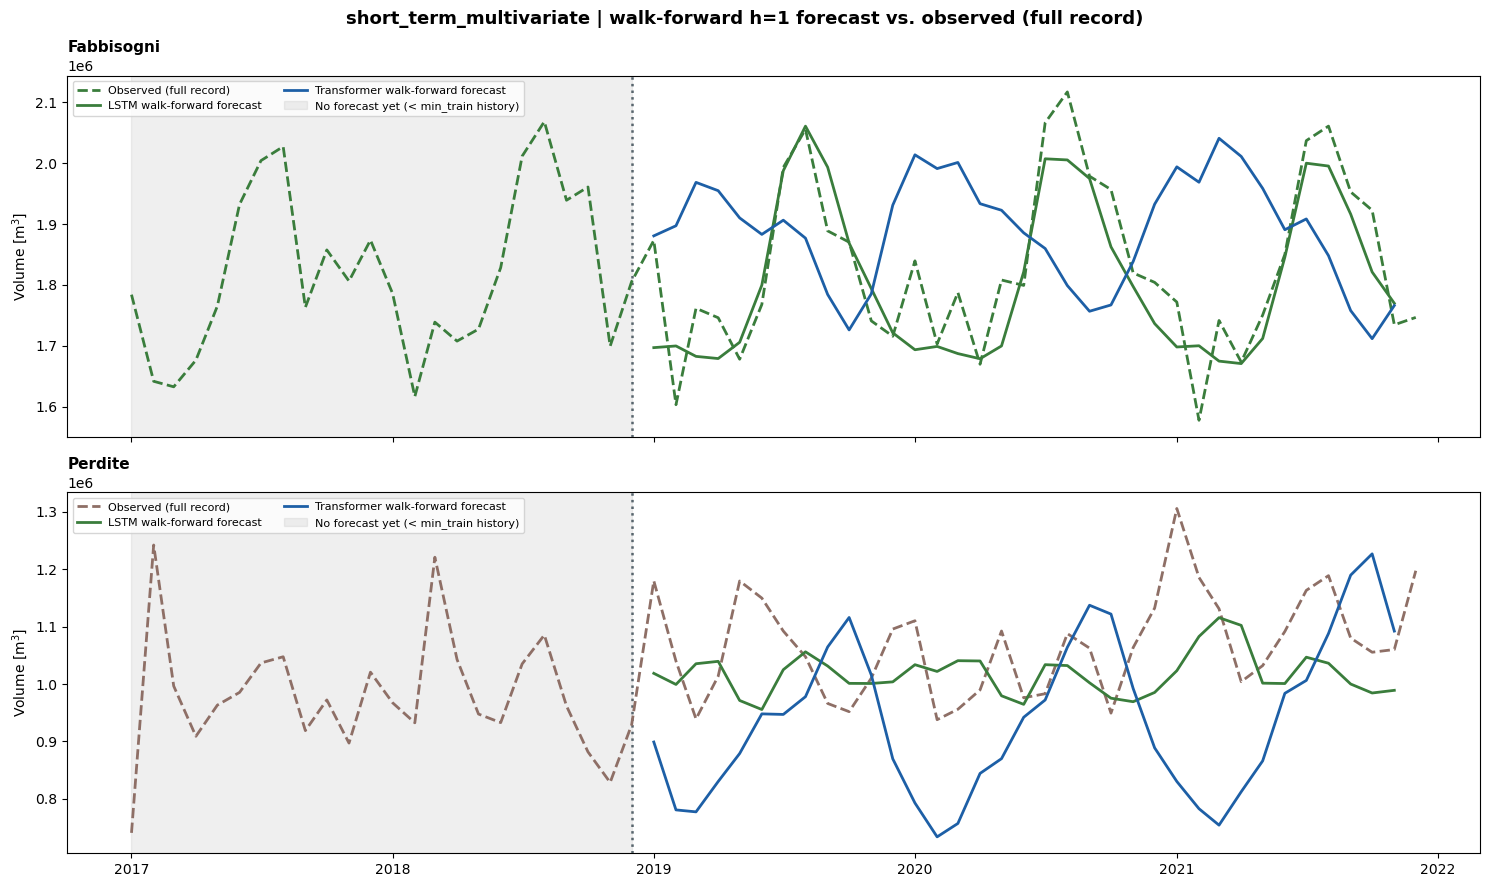

  Saved: output_v2\short_term_multivariate_h1_nse_comparison_fixed.svg


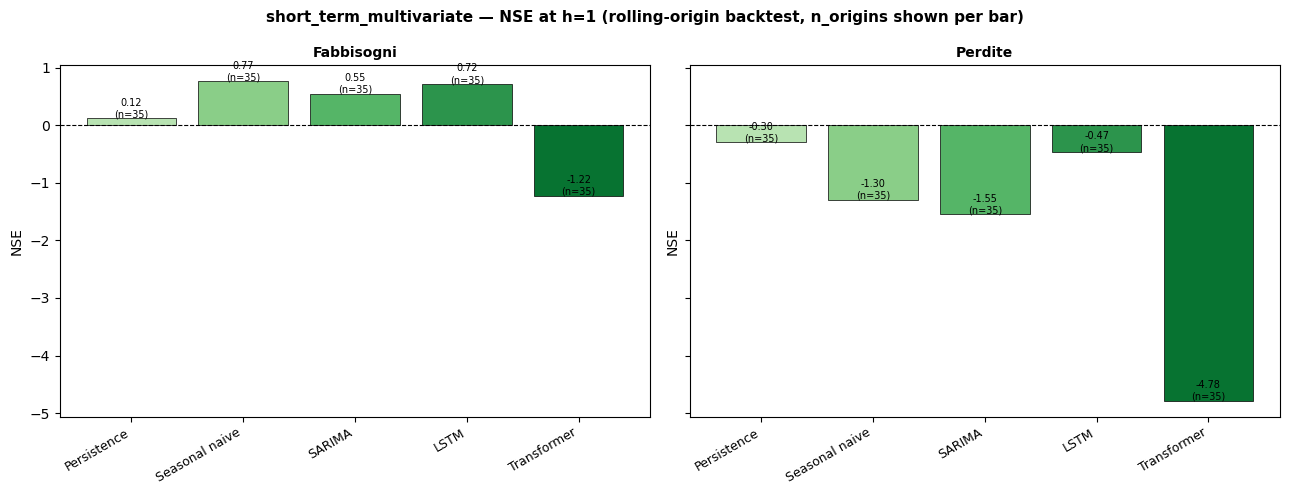

  Saved: output_v2\short_term_multivariate_h1_rolling_mae.svg


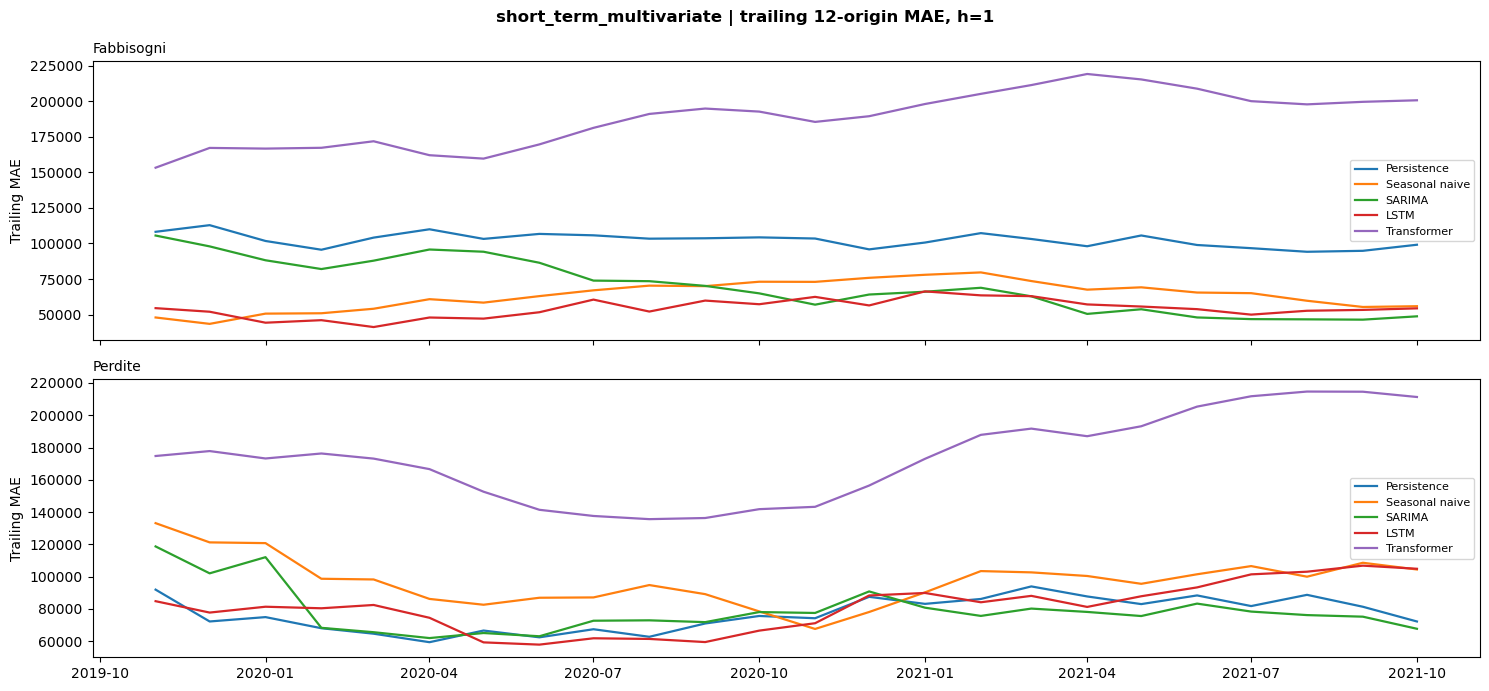


  Multi-seed DM test (HLN-corrected), LSTM vs Transformer, h=1:
    Fabbisogni   | median DM=-4.58, significant (p<0.05) in 100% of 5 usable seeds
    Perdite      | median DM=-5.27, significant (p<0.05) in 80% of 5 usable seeds

  short_term_autoregressive (5 seeds)
  [short_term_autoregressive_seed42] 34 rolling origins (first=24, last=57, stride=1, mode=static)
  [short_term_autoregressive_seed43] 34 rolling origins (first=24, last=57, stride=1, mode=static)
  [short_term_autoregressive_seed44] 34 rolling origins (first=24, last=57, stride=1, mode=static)
  [short_term_autoregressive_seed45] 34 rolling origins (first=24, last=57, stride=1, mode=static)
  [short_term_autoregressive_seed46] 34 rolling origins (first=24, last=57, stride=1, mode=static)

  NSE (mean +/- std across 5 seeds) at h=1:
  -- Fabbisogni --
    Persistence      NSE=+0.128 +/- 0.000   KGE=+0.562 +/- 0.000
    Seasonal naive   NSE=+0.777 +/- 0.000   KGE=+0.886 +/- 0.000
    SARIMA           NSE=+0.589 +/- 0.000 

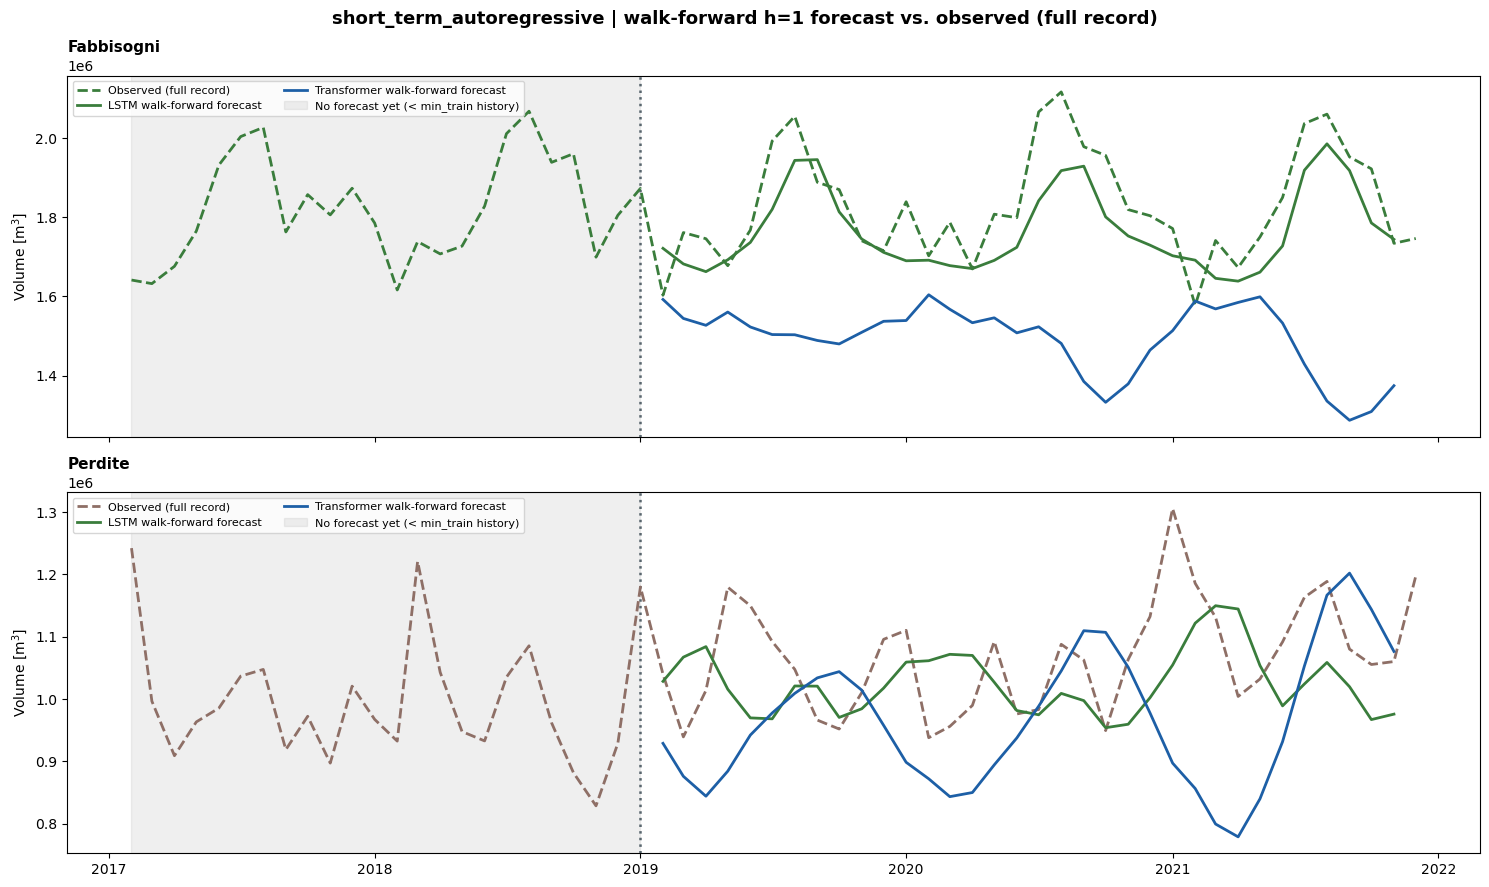

  Saved: output_v2\short_term_autoregressive_h1_nse_comparison_fixed.svg


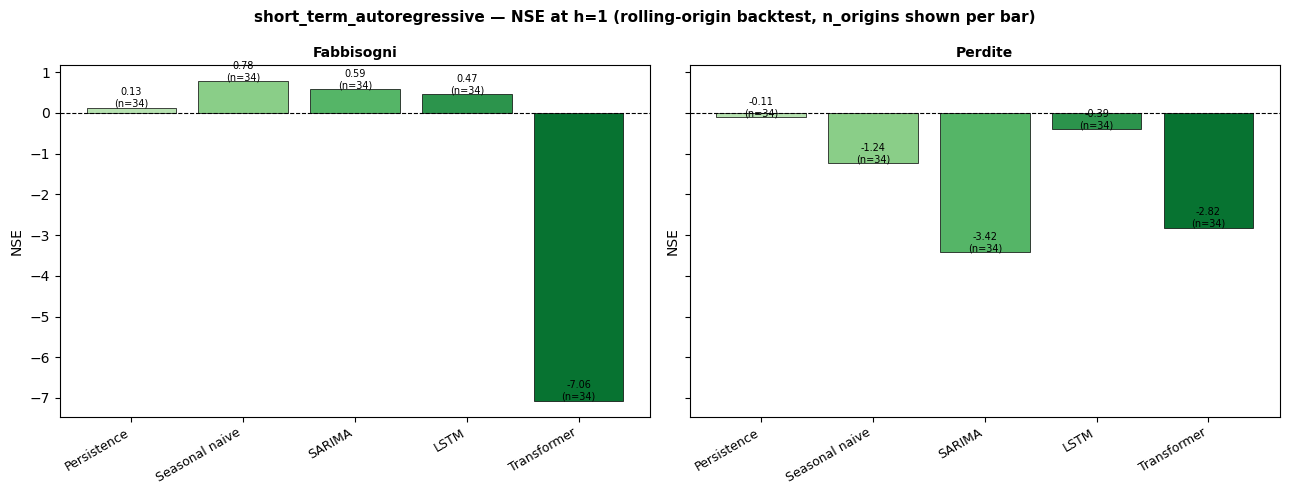

  Saved: output_v2\short_term_autoregressive_h1_rolling_mae.svg


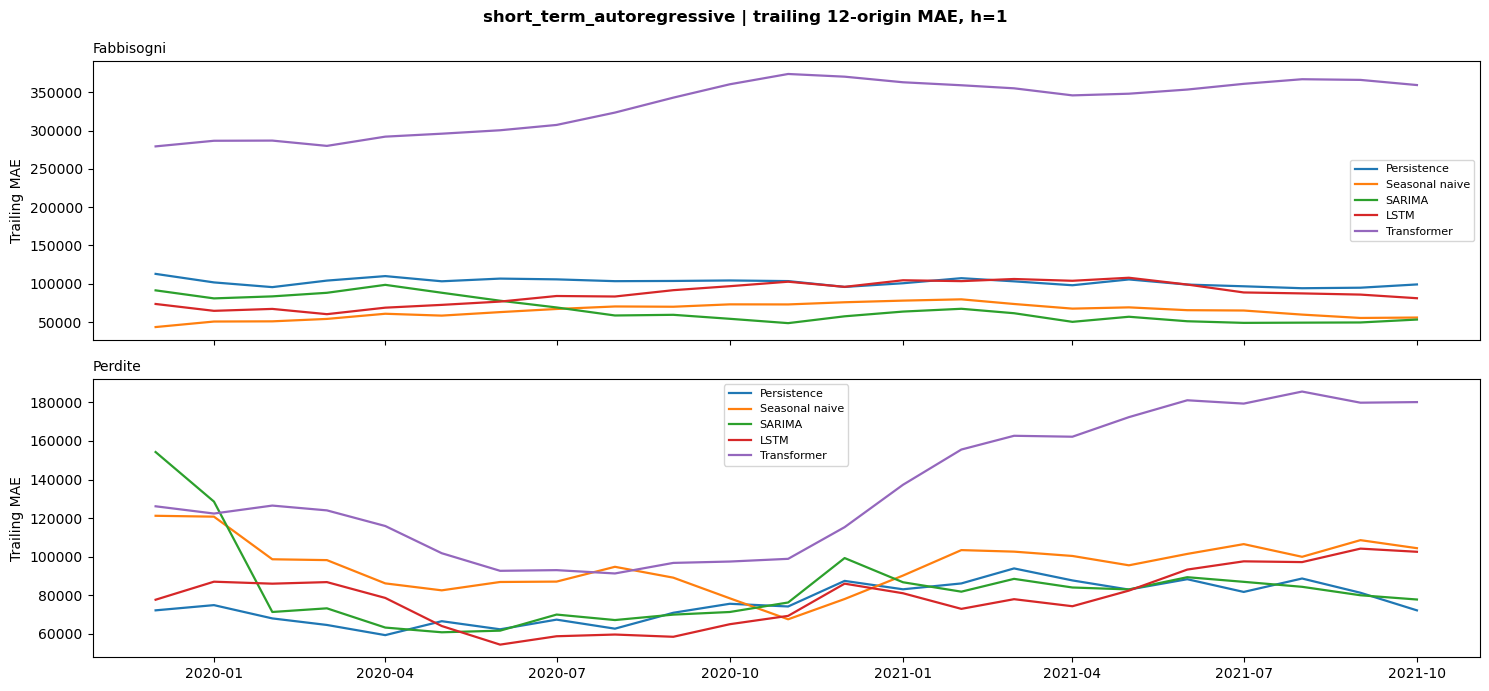


  Multi-seed DM test (HLN-corrected), LSTM vs Transformer, h=1:
    Fabbisogni   | median DM=-5.31, significant (p<0.05) in 80% of 5 usable seeds
    Perdite      | median DM=-3.52, significant (p<0.05) in 80% of 5 usable seeds

  long_term_multivariate (5 seeds)
  [long_term_multivariate_seed42] 18 rolling origins (first=31, last=48, stride=1, mode=expanding)
  [long_term_multivariate_seed43] 18 rolling origins (first=31, last=48, stride=1, mode=expanding)
  [long_term_multivariate_seed44] 18 rolling origins (first=31, last=48, stride=1, mode=expanding)
  [long_term_multivariate_seed45] 18 rolling origins (first=31, last=48, stride=1, mode=expanding)
  [long_term_multivariate_seed46] 18 rolling origins (first=31, last=48, stride=1, mode=expanding)

  NSE (mean +/- std across 5 seeds) at h=1:
  -- Fabbisogni --
    Persistence      NSE=+0.185 +/- 0.000   KGE=+0.603 +/- 0.000
    Seasonal naive   NSE=+0.659 +/- 0.000   KGE=+0.845 +/- 0.000
    SARIMA           NSE=+0.519 +/- 0.000   KG

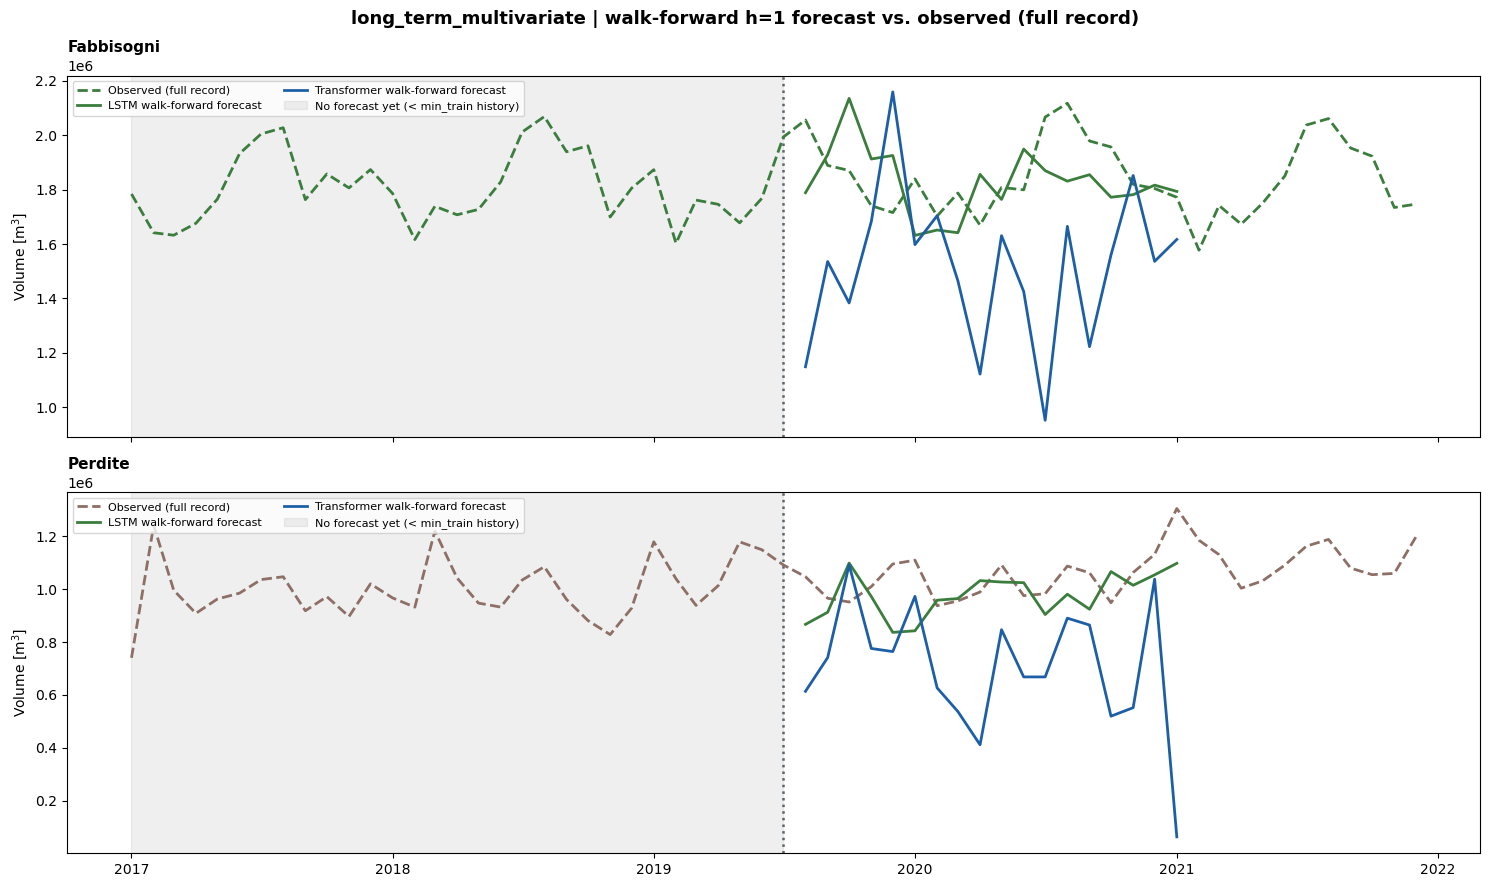

  Saved: output_v2\long_term_multivariate_h1_nse_comparison_fixed.svg


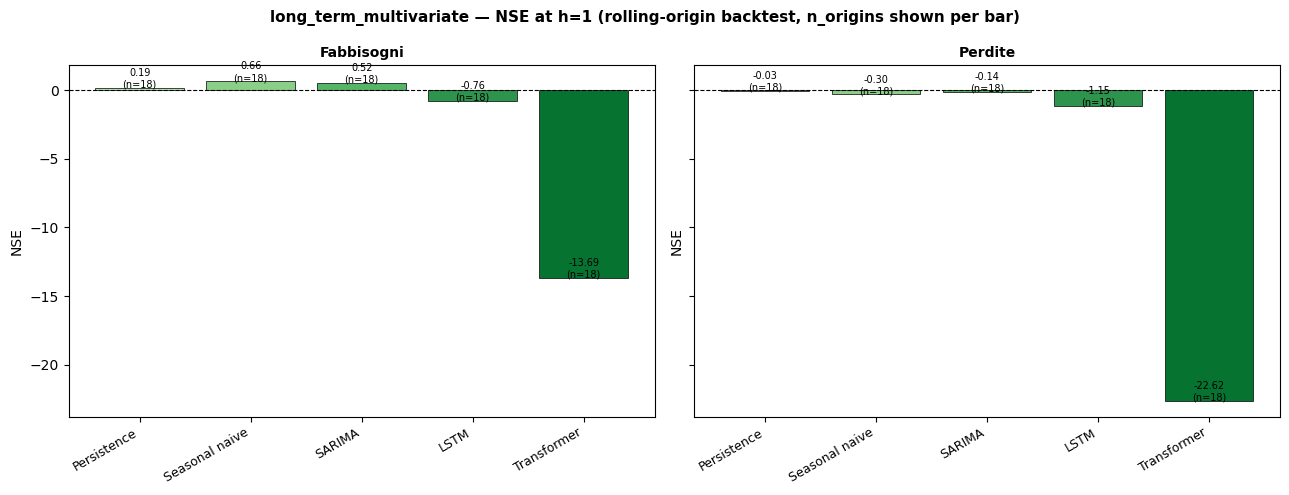

  Saved: output_v2\long_term_multivariate_h1_rolling_mae.svg


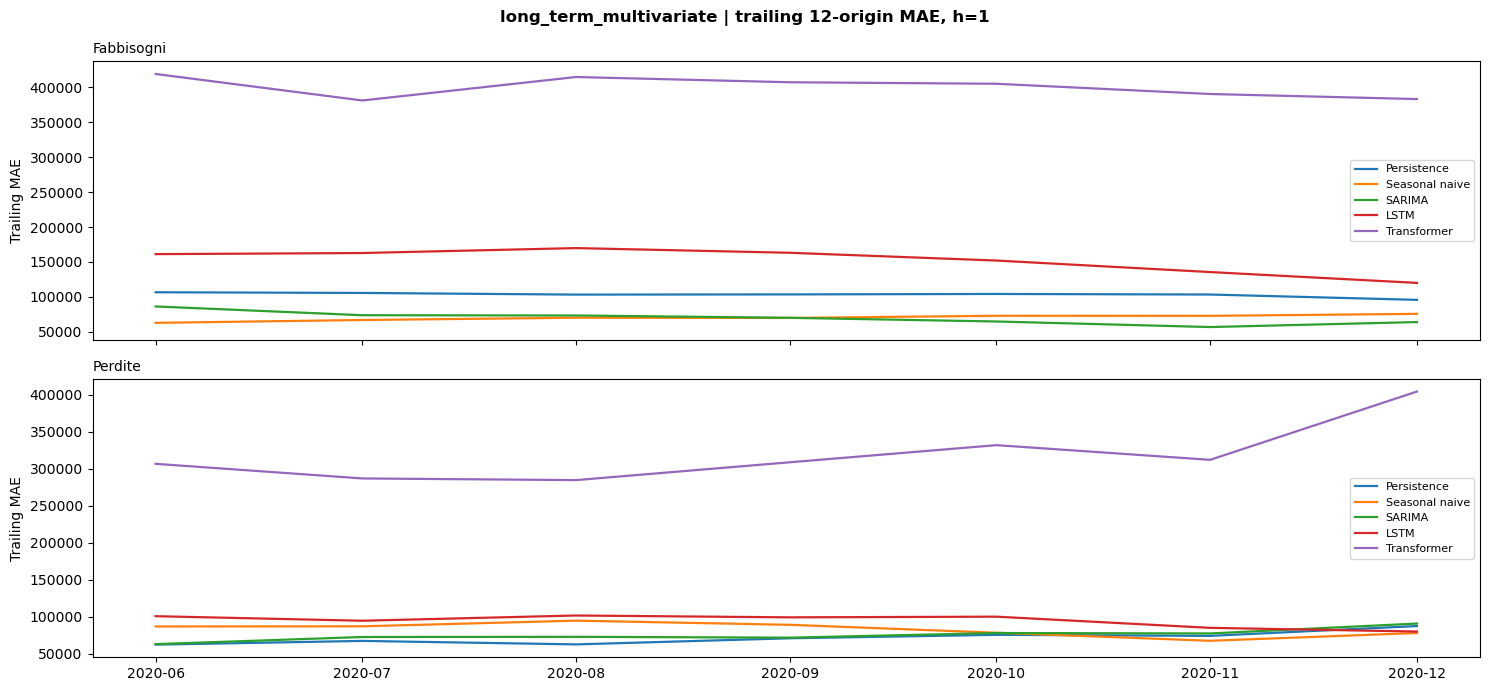


  Multi-seed DM test (HLN-corrected), LSTM vs Transformer, h=1:
    Fabbisogni   | median DM=-2.91, significant (p<0.05) in 100% of 5 usable seeds
    Perdite      | median DM=-3.49, significant (p<0.05) in 80% of 5 usable seeds

  long_term_autoregressive (5 seeds)
  [long_term_autoregressive_seed42] 17 rolling origins (first=31, last=47, stride=1, mode=expanding)
  [long_term_autoregressive_seed43] 17 rolling origins (first=31, last=47, stride=1, mode=expanding)
  [long_term_autoregressive_seed44] 17 rolling origins (first=31, last=47, stride=1, mode=expanding)
  [long_term_autoregressive_seed45] 17 rolling origins (first=31, last=47, stride=1, mode=expanding)
  [long_term_autoregressive_seed46] 17 rolling origins (first=31, last=47, stride=1, mode=expanding)

  NSE (mean +/- std across 5 seeds) at h=1:
  -- Fabbisogni --
    Persistence      NSE=+0.062 +/- 0.000   KGE=+0.566 +/- 0.000
    Seasonal naive   NSE=+0.601 +/- 0.000   KGE=+0.815 +/- 0.000
    SARIMA           NSE=+0.596 +

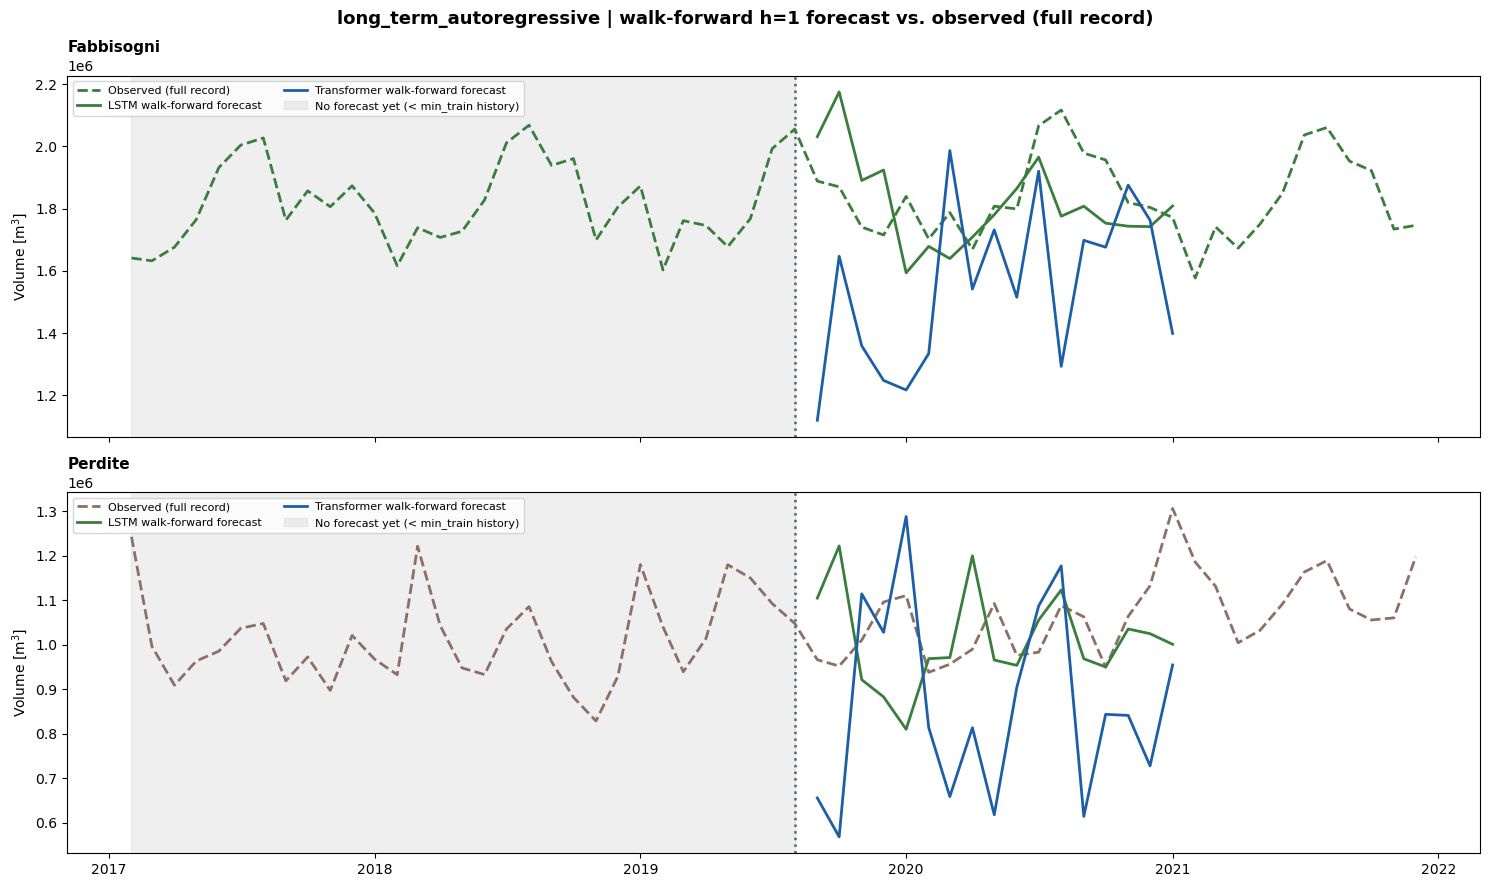

  Saved: output_v2\long_term_autoregressive_h1_nse_comparison_fixed.svg


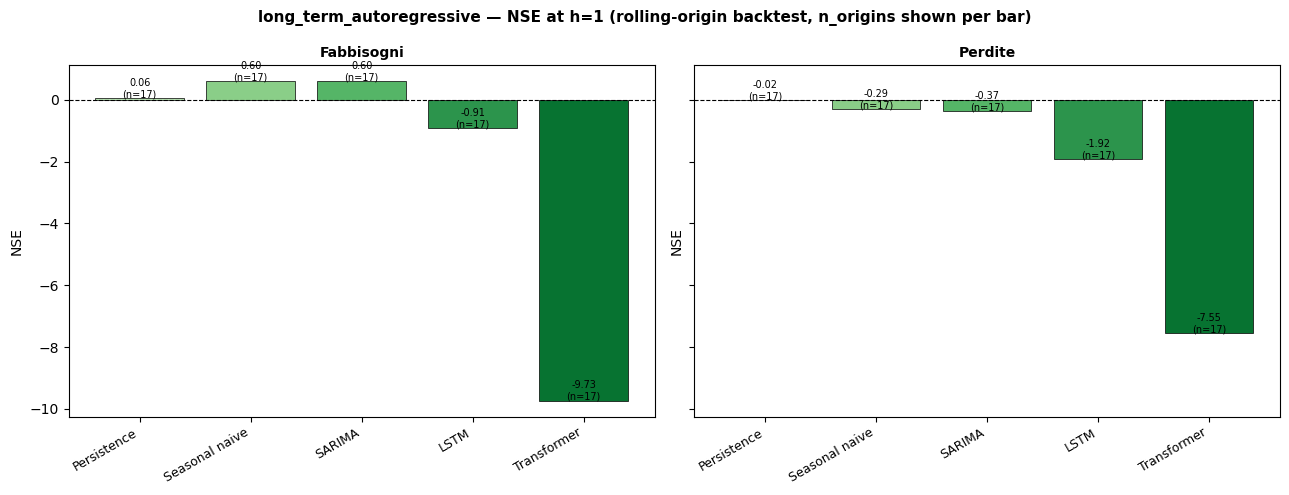

  Saved: output_v2\long_term_autoregressive_h1_rolling_mae.svg


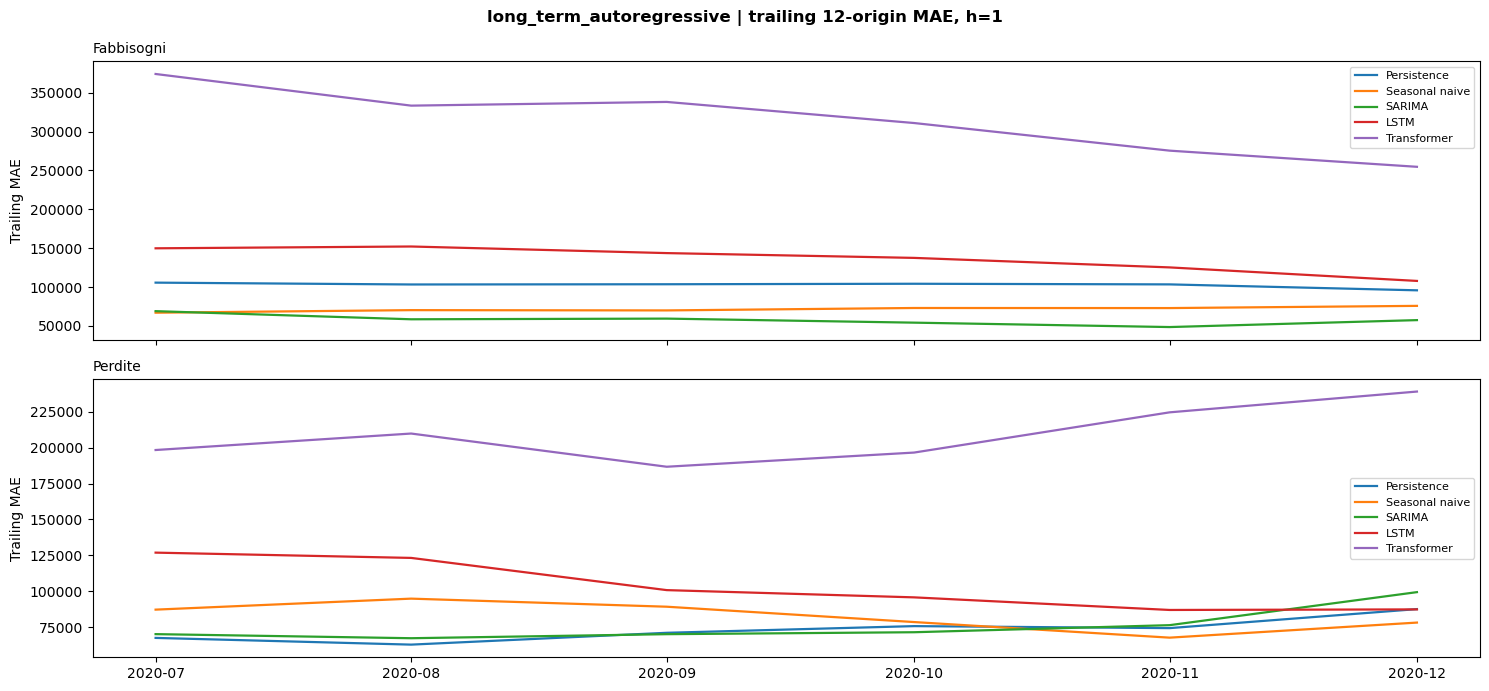


  Multi-seed DM test (HLN-corrected), LSTM vs Transformer, h=1:
    Fabbisogni   | median DM=-3.23, significant (p<0.05) in 100% of 5 usable seeds
    Perdite      | median DM=-2.81, significant (p<0.05) in 80% of 5 usable seeds


Saved -> output_v2\master_metrics_v2_agg.csv (mean+-std across seeds)
Saved -> output_v2\master_metrics_v2_per_seed.csv (every individual seed, for transparency)

Mean NSE per model x experiment (h=1, averaged across seeds):
model                       LSTM  Persistence  SARIMA  Seasonal naive  Transformer
experiment                                                                        
long_term_autoregressive  -0.979        0.023   0.110           0.154       -8.224
long_term_multivariate    -0.916        0.078   0.190           0.178      -13.062
short_term_autoregressive -0.108        0.010  -1.415          -0.229       -8.269
short_term_multivariate    0.058       -0.086  -0.499          -0.264       -7.076


In [18]:
df = load_data(DATA_PATH)
df = add_calendar_features(df)
base_feats = features + ['month_sin', 'month_cos', 'year_idx']

all_agg, all_combined = [], []
for exp_name, cfg in EXPERIMENTS.items():
    for input_cfg in ('multivariate', 'autoregressive'):
        tag = f"{exp_name}_{input_cfg}"
        print(f"\n{'='*72}\n  {tag} ({N_SEEDS} seeds)\n{'='*72}")

        if input_cfg == 'autoregressive':
            df_use = add_autoregressive_inputs(df.copy(), n_lags=1)
            feat_cols = base_feats + [f'{t}_lag1' for t in targets]
        else:
            df_use, feat_cols = df.copy(), base_feats

        this_min_train = min_train_for_cfg(cfg)
        this_mode = 'expanding' if exp_name == 'long_term' else 'static'

        per_seed_bt, combined, agg = run_multi_seed_backtest(
            df_use, feat_cols, cfg, this_mode, this_min_train, tag)
        agg['experiment'] = tag
        all_agg.append(agg)
        combined['experiment'] = tag
        all_combined.append(combined)

        h1 = agg[agg['horizon'] == 1]
        print(f"\n  NSE (mean +/- std across {N_SEEDS} seeds) at h=1:")
        for tgt in targets:
            sub = h1[h1['target']==tgt].set_index('model')
            print(f"  -- {tgt} --")
            for model in ['Persistence', 'Seasonal naive', 'SARIMA', 'LSTM', 'Transformer']:
                if model in sub.index:
                    row = sub.loc[model]
                    print(f"    {model:16s} NSE={row['NSE_mean']:+.3f} +/- {row['NSE_std']:.3f}   "
                         f"KGE={row['KGE_mean']:+.3f} +/- {row['KGE_std']:.3f}")

        # Plots use the first seed as a representative single run.
        first_seed = SEED_LIST[0]
        bt_repr = per_seed_bt[first_seed]
        metrics_repr = summarize_backtest(bt_repr, mase_denoms={tgt: mase_scale(df_use[tgt].values) for tgt in targets})
        plot_combined_series(bt_repr, df_use, tag, horizon=1)
        plot_nse_bar_chart_fixed(metrics_repr, tag, horizon=1)
        if cfg['future_steps'] > 1:
            plot_metric_evolution(bt_repr, tag, horizon=1)

        print(f"\n  Multi-seed DM test (HLN-corrected), LSTM vs Transformer, h=1:")
        for tgt in targets:
            res = multi_seed_dm_test(per_seed_bt, 'LSTM', 'Transformer', tgt, h=1)
            if res is None:
                print(f"    {tgt:12s} | insufficient paired predictions across seeds")
            else:
                print(f"    {tgt:12s} | median DM={res['median_DM']:+.2f}, significant (p<0.05) in "
                     f"{res['frac_seeds_significant']*100:.0f}% of {res['n_seeds_used']} usable seeds")

master_agg = pd.concat(all_agg, ignore_index=True)
master_combined = pd.concat(all_combined, ignore_index=True)
master_agg.to_csv(OUTPUT_DIR / 'master_metrics_v2_agg.csv', index=False)
master_combined.to_csv(OUTPUT_DIR / 'master_metrics_v2_per_seed.csv', index=False)
print(f"\n\nSaved -> {OUTPUT_DIR / 'master_metrics_v2_agg.csv'} (mean+-std across seeds)")
print(f"Saved -> {OUTPUT_DIR / 'master_metrics_v2_per_seed.csv'} (every individual seed, for transparency)")
print("\nMean NSE per model x experiment (h=1, averaged across seeds):")
print(master_agg[master_agg['horizon']==1].groupby(['experiment','model'])['NSE_mean']
            .mean().round(3).unstack('model').to_string())

## 8. Limitations

**Sample size.** N=60 monthly observations is small for any 12-step-ahead
deep learning comparison. Confidence intervals on any single NSE/KGE value
here should be assumed wide regardless of which fix or refinement has been
applied.

**Random-seed sensitivity.** `N_SEEDS=5` is a modest sample of the seed
distribution. The std values reported alongside every mean above are the
honest answer to "how much does this number move on its own" and should be
read together with the mean, not treated as a footnote.

**Single utility, single 60-month window.** Results are specific to ATO1
Marche Nord, 2017-2021. Generalization to other utilities, climates, or
time periods has not been tested.